In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

## Data loading

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
rhuh_dir = "Glioblastoma_RHUH-GBM_v2-29102025"
tcga_dir = "Glioblastoma_TCGA-GBM_v1-20170717"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1, 2, 3]
n_jobs = 16
nthreads = 2

DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

rhuh_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==2]["ID"].values]
rhuh_ids = [sub.replace('-0', '-', 1) for sub in rhuh_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{rhuh_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(rhuh_ids, desc="Loading RHUH maps")
)
maps_rhuh = np.vstack(results) # Nsubjects x nFeatures
maps_rhuh = np.where(maps_rhuh>=0, maps_rhuh, 0)

def delete_second_zero(text):
    splits = text.split('-')
    if len(splits) >= 3 and splits[2].startswith('0'):
        splits[2] = splits[2][1:]
    return '-'.join(splits)

tcga_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==3]["ID"].values]
tcga_ids = [delete_second_zero(sub) for sub in tcga_ids]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{tcga_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(tcga_ids, desc="Loading TCGA maps")
)
maps_tcga = np.vstack(results)
maps_tcga = np.where(maps_tcga>=0, maps_tcga, 0)

maps_all = np.vstack((maps_ucsf, maps_upenn, maps_rhuh, maps_tcga))

maps_training = np.vstack((maps_ucsf, maps_upenn))
maps_testing = np.vstack((maps_rhuh, maps_tcga))

Log-rank test: chi-squared statistic of 0.3129840079623018 (p=0.9575683269152051)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading TCGA maps: 100%|██████████| 103/103 [00:00<00:00, 128.14it/s]


## Datasets

In [3]:
from dataset import Dataset
from transformer import Transformer, Projector
from lifelines import CoxPHFitter
    
import matplotlib.pyplot as plt
from pipeline_encoder import EncodingPipeline
from results_saving import save_results

In [4]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1
RHUH_SITE_IDX = 2
TCGA_SITE_IDX = 3

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()
data_rhuh = DATA[DATA['site'] == RHUH_SITE_IDX].copy()
data_tcga = DATA[DATA['site'] == TCGA_SITE_IDX].copy()

data_training = pd.concat([data_ucsf, data_upenn], ignore_index=True)
data_testing = pd.concat([data_rhuh, data_tcga], ignore_index=True)

dataset_training = Dataset("ucsf+upenn", "path/1", maps_training, data_training)
dataset_testing = Dataset("rhuh+tcga", "path/2", maps_testing, data_testing)

df_training = dataset_training.df
df_testing = dataset_testing.df
training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

In [5]:
duration_col = 'OS (corrected)'
event_col = 'status'

## Execute feature extraction method

In [6]:
from TractDensityComponents import TD_PCA


normalization = None
n_components= 100

method = TD_PCA(maps_training, T1, binary_mask=T1_brain, n_components=n_components)
trainer = Transformer(method)
comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!


### Prepare data

In [7]:
from data_transformer import DataTransformer


df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
encoding_pipeline = EncodingPipeline(X_train_with_features)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "ID", "ltdi", "tdi", "volume"])
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

## CoxPHFitter lifelines

In [8]:
from lifelines import CoxPHFitter


penalizers = np.arange(0.001, 1.5, 0.1)
l1_ratios = np.arange(0.001, 1, 0.1)


for penalizer in penalizers:
    for l1_ratio in l1_ratios:
        cph = CoxPHFitter(penalizer=penalizer, l1_ratio=l1_ratio)
        try:
            cph.fit(X_train, duration_col, event_col)
        except Exception as e:
            print(f"Error fitting CoxPHFitter with penalizer={penalizer} and l1_ratio={l1_ratio}: {e}")
            continue

        train_c_index = cph.concordance_index_
        c_index_test = cph.score(X_test, "concordance_index")

        fig, ax = plt.subplots(figsize=(12, 20))
        ax.set_title(f"Baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer:.4f}\n Training Concordance Index on {dataset_training.name.upper()}: {cph.concordance_index_:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
        cph.plot(ax = ax)
        plot_filename = f"results-pca/pca-lifelines/cox_plot_penalizer_{penalizer:.3f}_l1_ratio_{l1_ratio:.3f}.png"
        fig.savefig(plot_filename, bbox_inches='tight')
        plt.close(fig)

        clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]
        results = {
            "extraction_method": "PCA",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "penalizer": penalizer,
            "l1_ratio": l1_ratio,
            "cox_method": "CoxPHFitter",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results-pca/pca_100_components_lifelines.csv")

## Scikit-survival ridge regression

### Prepare datasets for scikit-survival input format

In [9]:
y_train = np.array(
    list(zip(X_train[event_col].astype(bool), X_train[duration_col])),
    dtype=[('Status', '?'), ('Time', '<f8')]
)

y_test = np.array(
    list(zip(X_test[event_col].astype(bool), X_test[duration_col])),
    dtype=[('Status', '?'), ('Time', '<f8')]
)
X_train = X_train.drop(columns=[event_col, duration_col])
X_test = X_test.drop(columns=[event_col, duration_col])

In [10]:
def plot(cph_fitter, ax, plot_filename, title):
    coef_df = pd.DataFrame({
            "Feature": X_train.columns,
            "Coefficient": cph_fitter.coef_
    })
        
    coef_df = coef_df.sort_values(by="Coefficient", ascending=True)
        
    # colors = ['#2ecc71' if c < 0 else '#e74c3c' for c in coef_df["Coefficient"]]
    
    ax.barh(coef_df["Feature"], coef_df["Coefficient"], edgecolor="black", alpha=0.8)
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("Coefficient weights (Log Hazard Ratio)", fontsize=12, fontweight='bold')
    ax.set_ylabel("Features", fontsize=12, fontweight='bold')
    ax.grid(True, axis='x', linestyle=':', alpha=0.7)

    fig.savefig(plot_filename, bbox_inches='tight')
    plt.close(fig)

In [11]:
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

alpha = 0.01
alphas = 10.0 ** np.linspace(-4, 4, 100)

for alpha in alphas:
        cph_ridge = CoxPHSurvivalAnalysis(alpha=alpha)
        try:
            cph_ridge.fit(X_train, y_train)
        except Exception as e:
            print(f"Error fitting CoxPHSurvivalAnalysis with alpha={alpha}: {e}")
            continue
        
        train_c_index = cph_ridge.score(X_train, y_train)
        c_index_test = cph_ridge.score(X_test, y_test)

        fig, ax = plt.subplots(figsize=(12, 20))
        plot_filename = f"results-pca/pca-sksurv-ridge/cox_plot_alpha_{alpha:.3f}.png"
        title = (
            f"Coefficient Weights (Trained on {dataset_training.name.upper()})\n"
            f"Alpha: {alpha:.4f}\n" 
            f"Train C-Index: {train_c_index:.4f} | Test C-Index: {c_index_test:.4f}"
        )
        plot(cph_ridge, ax, plot_filename, title)

        clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]
        results = {
            "extraction_method": "PCA",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "alpha": alpha,
            "cox_method": "CoxPHSurvivalAnalysis",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results-pca/pca_100_components_scikit_surv.csv")

In [12]:
def plot_2(cph_fitter, ax, plot_filename, title):
    import numpy as np
    
    coefficients = np.ravel(cph_fitter.coef_)
    
    coef_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Coefficient": coefficients
    })
    
    coef_df = coef_df.sort_values(by="Coefficient", ascending=True)
    
    # colors = ['#2ecc71' if c < 0 else '#e74c3c' for c in coef_df["Coefficient"]]
    ax.barh(coef_df["Feature"], coef_df["Coefficient"], edgecolor="black", alpha=0.8)
    ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("Coefficient weights (Log Hazard Ratio)", fontsize=12, fontweight='bold')
    ax.set_ylabel("Features", fontsize=12, fontweight='bold')
    ax.grid(True, axis='x', linestyle=':', alpha=0.7)

    fig.savefig(plot_filename, bbox_inches='tight')
    plt.close(fig)

/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: all coefficients are zero, consider decreasing alpha.
  cph.fit(X_train, y_train)
/tmp/ipykernel_950657/3212429199.py:14: UserWarning: al

KeyboardInterrupt: 

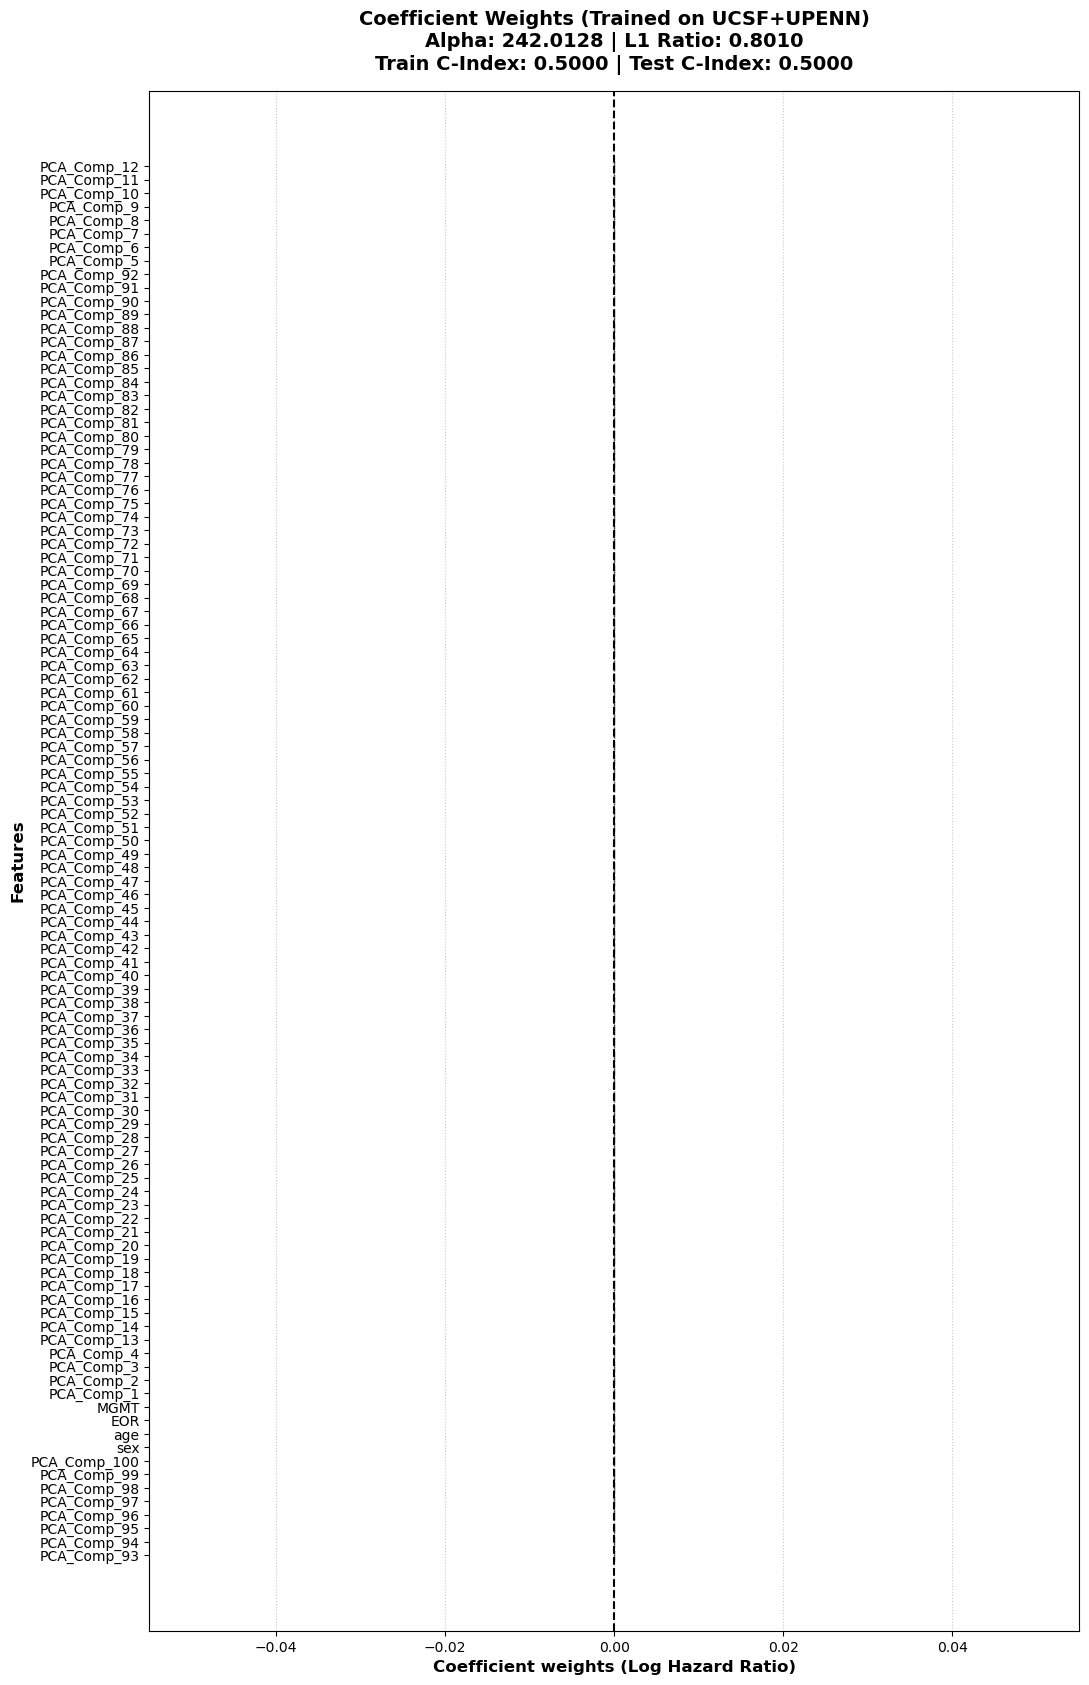

In [15]:
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis



clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]

alphas = 10.0 ** np.linspace(-4, 4, 100)
l1_ratios = np.arange(0.001, 1, 0.1)

for alpha in alphas:
    for l1_ratio in l1_ratios:
        cph = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio, alphas=[alpha])
        try:
            cph.fit(X_train, y_train)
        except Exception as e:
            print(f"Error fitting CoxnetSurvivalAnalysis with alpha={alpha}: {e}")
            continue
        
        train_c_index = cph.score(X_train, y_train)
        c_index_test = cph.score(X_test, y_test)

        fig, ax = plt.subplots(figsize=(12, 20))
        title = (
            f"Coefficient Weights (Trained on {dataset_training.name.upper()})\n"
            f"Alpha: {alpha:.4f} | L1 Ratio: {l1_ratio:.4f}\n" 
            f"Train C-Index: {train_c_index:.4f} | Test C-Index: {c_index_test:.4f}"
        )
        plot_filename = f"results-pca/pca-sksurv-elastic/cox_plot_l1_ratio_{l1_ratio:.3f}_alphas_{alpha:.3f}.png"
        plot_2(cph, ax, plot_filename, title)

        results = {
            "extraction_method": "PCA",
            "training_dataset": dataset_training.name,
            "testing_dataset": dataset_testing.name,
            "alpha": alpha,
            "l1_ratio": l1_ratio,
            "cox_method": "CoxnetSurvivalAnalysis",
            "ci_training": round(train_c_index, 5),
            "ci_testing": round(c_index_test, 5),
            "covariates": clean_covariates,
            "duration_col": duration_col,
            "event_col": event_col
        }

        save_results(results, "results-pca/pca-100-comps-scikit-surv-elastic.csv")

In [16]:
from sksurv.ensemble import RandomSurvivalForest


clean_covariates = [col for col in X_train.columns if col not in [duration_col, event_col]]

n_estimators = np.arange(100, 1500, 100)
min_samples_leaf = np.arange(1, 30, 5)
min_samples_split = np.arange(0.1, 1, 0.2).tolist() + np.arange(2, 20, 5).tolist()

for n_est in n_estimators:
    for min_leafs in min_samples_leaf:
        for min_split in min_samples_split:
            rsf = RandomSurvivalForest(
                n_estimators=n_est, min_samples_split=min_split, min_samples_leaf=min_leafs, n_jobs=-1
            )
            try:
                rsf.fit(X_train, y_train)
            except Exception as e:
                print(f"Error fitting RandomSurvivalForest with n_estimators={n_est}: {e}")
                continue
        
            train_c_index = rsf.score(X_train, y_train)
            c_index_test = rsf.score(X_test, y_test)


            results = {
                "extraction_method": "PCA",
                "training_dataset": dataset_training.name,
                "testing_dataset": dataset_testing.name,
                "n_estimators": n_est,
                "min_samples_leaf": min_leafs,
                "min_samples_split": min_split,
                "cox_method": "RandomSurvivalForest",
                "ci_training": round(train_c_index, 5),
                "ci_testing": round(c_index_test, 5),
                "covariates": clean_covariates,
                "duration_col": duration_col,
                "event_col": event_col
            }

            save_results(results, "results-pca/pca-100-comps-sksurv-random-forest.csv")

KeyboardInterrupt: 

## Permutation importance

In [17]:
from sklearn.inspection import permutation_importance
from sksurv.ensemble import RandomSurvivalForest


rsf = RandomSurvivalForest(
    n_estimators=300, min_samples_split=0.5, min_samples_leaf=16, n_jobs=-1,
)
rsf.fit(X_train, y_train)
result = permutation_importance(rsf, X_test, y_test, n_repeats=5, random_state=20, n_jobs=-1)

In [18]:
pd.DataFrame(
    {
        k: result[k]
        for k in (
            "importances_mean",
            "importances_std",
        )
    },
    index=X_test.columns,
).sort_values(by="importances_mean", ascending=False)

,importances_mean,importances_std
age,0.078708,0.019614
PCA_Comp_34,0.010444,0.007430
PCA_Comp_3,0.007492,0.002939
PCA_Comp_54,0.005320,0.002392
MGMT,0.002702,0.003482
...,...,...
PCA_Comp_43,-0.004122,0.001745
PCA_Comp_42,-0.007520,0.002761
PCA_Comp_57,-0.007659,0.005222
PCA_Comp_51,-0.008467,0.008110
